# SCIKIT-LEARN MASTERY — NOTEBOOK 14 (FINAL)
## Chapters 78–97: Professional Engineering Discipline → Full Interview Mastery → Master Capstone → Mock Interview

This is the final notebook of the course. It closes with an independent capstone project and a mock-interview self-assessment.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–77 *(Notebooks 1–13, including all 6 industry projects)*
- [x] Professional Project Structure
- [x] Testing ML Code
- [x] Data Validation
- [x] ML Error Analysis (consolidated)
- [x] Model Card / Documentation
- [x] Interview Mastery (Beginner → Expert)
- [x] Scikit-learn Coding Interview
- [x] Debugging Interview
- [x] Real-World Architecture Questions
- [x] Scikit-learn vs Other ML Libraries
- [x] NumPy+Pandas+Seaborn+Scikit-learn Combined Workflows
- [x] Professional Notebook Engineering
- [x] Production Code vs Notebook Code
- [x] Performance Engineering
- [x] Security and Model Persistence
- [x] Model Governance
- [x] Business Interpretation
- [x] Model Selection Masterclass
- [x] **Master Capstone**
- [x] **Mock Interview**

**Full course progress: 97/97 chapters complete.**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
np.random.seed(42)


---
# CHAPTER 78 — PROFESSIONAL PROJECT STRUCTURE

## The Standard Layout
```
ml-project/
├── data/
│   ├── raw/              -- never modified after initial collection
│   └── processed/        -- cleaned/feature-engineered outputs, reproducible from raw/ + src/
├── notebooks/             -- exploration, numbered by workflow stage
│   ├── 01_eda.ipynb
│   ├── 02_feature_engineering.ipynb
│   ├── 03_baseline.ipynb
│   └── 04_model_selection.ipynb
├── src/                    -- STABLE, TESTED, reusable code (never exploratory)
│   ├── data.py             -- loading/cleaning functions
│   ├── preprocessing.py    -- ColumnTransformer/Pipeline construction
│   ├── features.py         -- custom transformers (Chapter 9)
│   ├── train.py            -- training entry point
│   ├── evaluate.py         -- evaluation/reporting functions
│   └── predict.py          -- inference entry point
├── models/                 -- persisted joblib artifacts + metadata (Chapter 67)
├── reports/                -- generated figures, business-facing summaries
├── tests/                  -- unit tests for src/ (Chapter 79)
├── requirements.txt        -- pinned dependency versions (Chapter 66)
├── README.md
└── config/                 -- hyperparameters, paths, thresholds -- NOT hardcoded in src/
```

## The Core Principle
**Notebooks are for exploration and communication; `src/` is for anything that needs to be correct, tested, and reused.** The moment a notebook cell's logic is needed a second time (in another notebook, in a training script, in production inference), it should move into `src/` and be imported — exactly the "promote to a module" discipline established in the Matplotlib course's Chapter 87, now applied to an entire project's structure, not just visualization code.


In [2]:
# A minimal, CONCRETE illustration: the exact same function, first as notebook-cell logic,
# then promoted to src/-style, testable code

# --- Notebook-cell version (fine for initial EDA, NOT fine to keep here long-term) ---
def clean_income_column_v1(df):
    df["income"] = df["income"].fillna(df["income"].median())
    df = df[df["income"] > 0]   # remove impossible negative incomes
    return df

# --- src/data.py -style version: documented, type-hinted, defensive, testable ---
def clean_income_column(df: pd.DataFrame, income_col: str = "income") -> pd.DataFrame:
    """Impute missing income with the median and drop rows with non-positive income.

    Args:
        df: Input DataFrame containing `income_col`.
        income_col: Name of the income column to clean.

    Returns:
        A new DataFrame (input is not mutated) with income cleaned.

    Raises:
        KeyError: if `income_col` is not present in `df`.
    """
    if income_col not in df.columns:
        raise KeyError(f"Expected column '{income_col}' not found in DataFrame.")
    df = df.copy()   # never mutate the caller's DataFrame -- Chapter 9's rule, applied project-wide
    df[income_col] = df[income_col].fillna(df[income_col].median())
    return df[df[income_col] > 0]


test_df = pd.DataFrame({"income": [50000, np.nan, -100, 60000]})
result = clean_income_column(test_df)
print(result)
print("\nThe src/ version: has a docstring, type hints, explicit error handling, and never")
print("mutates its input -- exactly what makes it safe to import and reuse across notebooks,")
print("training scripts, AND unit tests (Chapter 79).")


    income
0  50000.0
1  50000.0
3  60000.0

The src/ version: has a docstring, type hints, explicit error handling, and never
mutates its input -- exactly what makes it safe to import and reuse across notebooks,
training scripts, AND unit tests (Chapter 79).


### Interview Insight
**Q: A teammate has all their project logic in a single 400-cell Jupyter notebook. What specific risks does this create, and how would you propose restructuring it?**
A: Key risks: no version control granularity (a single notebook's diffs are hard to review meaningfully), no reuse across notebooks/training/inference without copy-paste (leading to drift when one copy is fixed and others aren't), no unit testing (Chapter 79), and cell-execution-order bugs (a notebook can "work" in a stale kernel state that doesn't reflect a fresh top-to-bottom run). I'd propose extracting stable, reusable logic (data loading, preprocessing, custom transformers, evaluation functions) into a `src/` package with proper functions/classes, tests, and docstrings — keeping notebooks focused specifically on exploration, one-off analysis, and communicating results, importing from `src/` rather than redefining logic inline.

### Quiz (Chapter 78)
1. What's the core principle distinguishing what belongs in `notebooks/` versus `src/`?
2. Why does the `src/`-style function check for the column's existence explicitly and raise a clear error?
3. What specific project-management risks does an all-in-one-notebook project structure create?


---
# CHAPTER 79 — TESTING ML CODE

## What Should Be Tested
| Category | Example test |
|---|---|
| **Preprocessing correctness** | Does `clean_income_column` actually drop negative incomes and impute the correct median? |
| **Feature engineering correctness** | Does a custom transformer (Chapter 9) produce the exact expected output on a small, known input? |
| **Shape/schema contracts** | Does the fitted pipeline's output have the expected number of columns after `OneHotEncoder`? |
| **Prediction sanity** | Does the model's `predict_proba()` output always sum to 1 per row, stay within [0,1]? |
| **Model loading** | Does a persisted model load successfully and produce the exact same predictions as before saving (Chapter 66's own verification pattern, formalized as an actual test)? |


In [3]:
import unittest

class TestChurnPreprocessing(unittest.TestCase):
    """A genuine, runnable unittest suite for ML preprocessing code."""

    def setUp(self):
        self.sample_df = pd.DataFrame({"income": [50000, np.nan, -100, 60000]})

    def test_clean_income_drops_negative_values(self):
        result = clean_income_column(self.sample_df)
        self.assertTrue((result["income"] > 0).all(), "Negative incomes should be removed")

    def test_clean_income_imputes_missing_with_median(self):
        result_full = clean_income_column(self.sample_df.copy())
        # Median is computed BEFORE the >0 filter, over [50000, -100, 60000] -> median = 50000
        # (a good illustration of why "which step runs first" matters when reasoning about a
        # transformer's exact behavior -- always verify empirically, don't just assume!)
        self.assertIn(50000.0, result_full["income"].values)

    def test_clean_income_does_not_mutate_input(self):
        original_copy = self.sample_df.copy()
        clean_income_column(self.sample_df)
        pd.testing.assert_frame_equal(self.sample_df, original_copy)

    def test_missing_column_raises_key_error(self):
        with self.assertRaises(KeyError):
            clean_income_column(pd.DataFrame({"other_col": [1, 2, 3]}))


# Run the suite and report results (exactly what a CI pipeline would do automatically)
loader = unittest.TestLoader()
suite = loader.loadTestsFromTestCase(TestChurnPreprocessing)
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)
print(f"\n{result.testsRun} tests run, {len(result.failures)} failures, {len(result.errors)} errors")


test_clean_income_does_not_mutate_input (__main__.TestChurnPreprocessing.test_clean_income_does_not_mutate_input) ... ok
test_clean_income_drops_negative_values (__main__.TestChurnPreprocessing.test_clean_income_drops_negative_values) ... ok
test_clean_income_imputes_missing_with_median (__main__.TestChurnPreprocessing.test_clean_income_imputes_missing_with_median) ... ok
test_missing_column_raises_key_error (__main__.TestChurnPreprocessing.test_missing_column_raises_key_error) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.014s

OK



4 tests run, 0 failures, 0 errors


In [4]:
# A prediction SANITY test -- verifying model output properties hold regardless of the exact numbers
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification

class TestModelOutputContract(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        X, y = make_classification(n_samples=200, random_state=1)
        cls.model = LogisticRegression().fit(X, y)
        cls.X_test = X[:20]

    def test_predict_proba_sums_to_one(self):
        probas = self.model.predict_proba(self.X_test)
        np.testing.assert_allclose(probas.sum(axis=1), 1.0, atol=1e-8)

    def test_predict_proba_in_valid_range(self):
        probas = self.model.predict_proba(self.X_test)
        self.assertTrue((probas >= 0).all() and (probas <= 1).all())

    def test_predict_output_shape_matches_input(self):
        preds = self.model.predict(self.X_test)
        self.assertEqual(len(preds), len(self.X_test))


suite2 = loader.loadTestsFromTestCase(TestModelOutputContract)
result2 = runner.run(suite2)
print(f"\n{result2.testsRun} tests run, {len(result2.failures)} failures")


test_predict_output_shape_matches_input (__main__.TestModelOutputContract.test_predict_output_shape_matches_input) ... ok
test_predict_proba_in_valid_range (__main__.TestModelOutputContract.test_predict_proba_in_valid_range) ... ok
test_predict_proba_sums_to_one (__main__.TestModelOutputContract.test_predict_proba_sums_to_one) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.031s

OK



3 tests run, 0 failures


### Interview Insight
**Q: What kinds of tests make sense for an ML pipeline, given that model predictions themselves are inherently probabilistic and not deterministic in the way traditional software output is?**
A: Rather than testing "the model predicts exactly X," which would be brittle and often not even meaningful, ML tests focus on **contracts and invariants**: does preprocessing produce the expected shape/schema, does a custom transformer behave correctly on a small known input, does `predict_proba()` always sum to 1 and stay in [0,1], does a persisted-and-reloaded model produce identical predictions to the original, does the pipeline raise a clear error for malformed input rather than silently misbehaving. These tests catch a large class of real bugs (a preprocessing regression, a broken serialization round-trip, a schema mismatch) without requiring the model's actual predictions to be deterministically "correct" in some absolute sense.

### Quiz (Chapter 79)
1. Why can't ML tests typically assert "the model predicts exactly this value" the way traditional unit tests assert exact output?
2. Name three genuinely testable "contract" properties of a fitted classifier's output.
3. Why is `test_clean_income_does_not_mutate_input` a valuable test, connecting back to Chapter 9's transformer convention?


---
# CHAPTER 80 — DATA VALIDATION

## What to Check on Every New/Incoming Dataset
```python
shape, dtypes, missing values, categories, ranges, duplicates, target distribution
```


In [5]:
def validate_dataset(df: pd.DataFrame, expected_schema: dict, target_col: str = None) -> dict:
    """A genuine, reusable data validation function -- the kind that would run automatically
    at the START of every training run or before every batch inference job."""
    issues = []

    # 1. Schema: expected columns present with expected types
    for col, expected_dtype in expected_schema.items():
        if col not in df.columns:
            issues.append(f"MISSING COLUMN: '{col}'")
        else:
            try:
                type_ok = np.issubdtype(df[col].dtype, expected_dtype) or df[col].dtype == expected_dtype
            except TypeError:
                # pandas extension dtypes (e.g. modern "string" dtype) aren't valid numpy dtype
                # arguments -- fall back to a simple string-based comparison in that case
                type_ok = expected_dtype.__name__.lower() in str(df[col].dtype).lower()
            if not type_ok:
                issues.append(f"TYPE MISMATCH: '{col}' is {df[col].dtype}, expected {expected_dtype}")

    # 2. Missing values
    missing_pct = df.isna().mean() * 100
    high_missing = missing_pct[missing_pct > 30]
    if len(high_missing) > 0:
        issues.append(f"HIGH MISSINGNESS (>30%): {dict(high_missing.round(1))}")

    # 3. Duplicates
    n_dupes = df.duplicated().sum()
    if n_dupes > 0:
        issues.append(f"DUPLICATE ROWS: {n_dupes}")

    # 4. Target distribution (if applicable)
    if target_col and target_col in df.columns:
        target_balance = df[target_col].value_counts(normalize=True)
        if target_balance.min() < 0.02:
            issues.append(f"SEVERE TARGET IMBALANCE: {dict(target_balance.round(4))}")

    return {"passed": len(issues) == 0, "issues": issues, "shape": df.shape}


# Test against a deliberately FLAWED dataset
flawed_df = pd.DataFrame({
    "age": [25, 30, np.nan, np.nan, np.nan, 40] * 20,   # 50% missing
    "income": ["50000", "60000", "70000", "80000", "90000", "100000"] * 20,   # WRONG TYPE (string, not numeric)
    "churned": [0] * 119 + [1],   # severe imbalance
})
flawed_df = pd.concat([flawed_df, flawed_df.iloc[[0]]])   # inject a duplicate

expected_schema = {"age": np.floating, "income": np.number, "churned": np.integer}
report = validate_dataset(flawed_df, expected_schema, target_col="churned")

print(f"Validation passed: {report['passed']}")
print("Issues found:")
for issue in report["issues"]:
    print(" -", issue)


Validation passed: False
Issues found:
 - TYPE MISMATCH: 'income' is object, expected <class 'numpy.number'>
 - HIGH MISSINGNESS (>30%): {'age': np.float64(49.6)}
 - DUPLICATE ROWS: 114
 - SEVERE TARGET IMBALANCE: {0: np.float64(0.9917), 1: np.float64(0.0083)}


/tmp/ipykernel_754/3800587635.py:12: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  type_ok = np.issubdtype(df[col].dtype, expected_dtype) or df[col].dtype == expected_dtype


### Interview Insight
**Q: Why should data validation run automatically before every training run and every batch inference job, not just once during initial project setup?**
A: Upstream data sources change over time — a schema change, a new missingness pattern, a pipeline bug introducing duplicates, a shift in class balance — any of these can silently break a model trained under different assumptions, or silently degrade predictions without any explicit error. Running an automated validation check at the start of every training/inference run catches these issues at the earliest possible point (before they propagate into a trained model or a batch of predictions), turning a potentially subtle, hard-to-diagnose production issue into an immediate, clear, actionable failure — directly connecting to Chapter 71's monitoring discipline, but applied preventively at the input stage rather than reactively after the fact.

### Quiz (Chapter 80)
1. List the 7 categories of checks this chapter's `validate_dataset` function performs.
2. Why should this validation run automatically on every pipeline execution, not just once at project setup?
3. What real production incident could an automated schema/type check like this one have prevented?


---
# CHAPTER 81 — ML ERROR ANALYSIS (CONSOLIDATED)

## Beyond a Single Metric
Instead of stopping at `accuracy_score()`, professional error analysis asks:
```
Which examples are wrong?  →  Why?  →  Which class?  →  Which segment?  →  Which feature pattern?  →  Which business condition?
```
This directly consolidates Chapter 65 (Matplotlib course) and this course's Chapters 27–30, 58 into one systematic workflow.


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

np.random.seed(81)
n = 1000
error_analysis_df = pd.DataFrame({
    "feature_1": np.random.randn(n),
    "feature_2": np.random.randn(n),
    "segment": np.random.choice(["A", "B", "C"], n, p=[0.5, 0.3, 0.2]),
})
# Deliberately make the model genuinely WORSE for segment C (a realistic scenario: less
# training data or a genuinely different relationship for that segment)
true_logit = np.where(
    error_analysis_df["segment"] == "C",
    error_analysis_df["feature_1"] * 0.3,          # weak signal for segment C
    error_analysis_df["feature_1"] * 2.5 + error_analysis_df["feature_2"] * 1.5,   # strong signal elsewhere
)
error_analysis_df["target"] = (np.random.rand(n) < 1 / (1 + np.exp(-true_logit))).astype(int)

X_ea = error_analysis_df[["feature_1", "feature_2", "segment"]]
y_ea = error_analysis_df["target"]
X_ea_encoded = pd.get_dummies(X_ea, columns=["segment"])
X_train_ea, X_test_ea, y_train_ea, y_test_ea, seg_train, seg_test = train_test_split(
    X_ea_encoded, y_ea, error_analysis_df["segment"], test_size=0.3, random_state=81
)

model_ea = RandomForestClassifier(n_estimators=100, random_state=81).fit(X_train_ea, y_train_ea)
preds_ea = model_ea.predict(X_test_ea)

overall_accuracy = (preds_ea == y_test_ea.values).mean()
print(f"Overall accuracy: {overall_accuracy:.4f}  (looks fine in aggregate)")

# NOW disaggregate by segment -- the actual error analysis step
error_by_segment = pd.DataFrame({"segment": seg_test.values, "correct": (preds_ea == y_test_ea.values)})
segment_accuracy = error_by_segment.groupby("segment")["correct"].agg(["mean", "count"])
print("\nAccuracy by segment (WITH sample size, per the Matplotlib course's Chapter 65 lesson):")
print(segment_accuracy.round(4))


Overall accuracy: 0.7633  (looks fine in aggregate)

Accuracy by segment (WITH sample size, per the Matplotlib course's Chapter 65 lesson):
           mean  count
segment               
A        0.8079    151
B        0.8485     99
C        0.4600     50


### Interpretation
The overall accuracy number hides a real, actionable finding: segment C's accuracy is meaningfully worse than A/B — because the model was trained on data where segment C genuinely has a weaker predictive signal available in these features. This is exactly the kind of finding that only disaggregated error analysis (never a single overall metric) reveals — and it directly informs next steps: does segment C need different/additional features, a segment-specific model, or is this a fundamental limitation to document and communicate honestly to stakeholders (Chapter 82's Model Card)?

### Interview Insight
**Q: A model shows 90% overall accuracy, but a stakeholder asks whether it performs consistently across customer segments. Walk through your error analysis process.**
A: Disaggregate predictions by every meaningful segment (region, customer tier, any categorical grouping relevant to the business), computing accuracy (or the more relevant metric — precision/recall if imbalance matters within a segment) per group, always alongside each segment's sample size to avoid over-reacting to noise from a small group. For any segment showing meaningfully worse performance, dig further: is it a data quantity issue (fewer training examples for that segment), a genuinely weaker feature-target relationship for that segment, or a data quality issue specific to how that segment's data is collected? This turns a single aggregate number into an actionable, segment-level reliability picture — directly informing whether the model is safe to deploy uniformly, needs segment-specific treatment, or requires a documented limitation before shipping.

### Quiz (Chapter 81)
1. Why did the overall accuracy metric fail to reveal this project's actual weakness?
2. What must always accompany a segment-level error rate, and why?
3. What are three possible root causes for one segment consistently underperforming, and what would you check for each?


---
# CHAPTER 82 — MODEL CARD / DOCUMENTATION

## Concept
A **Model Card** is a standardized, concise document accompanying any deployed model — the practice originated from Google's 2019 "Model Cards for Model Reporting" paper and is now a widely-adopted industry norm, especially for models with real business/social impact.

## The Standard Sections


In [7]:
model_card_template = '''
# MODEL CARD: Customer Churn Prediction v1.0

## Model Purpose
Predicts the probability that an active subscription customer will churn within
the next 30 days, to prioritize retention-team outreach.

## Dataset
- Source: internal customer database, snapshot as of 2026-01-15
- Size: 2,996 customers (after data quality filtering)
- Target distribution: 37.3% churned (moderate imbalance)

## Features
tenure_months, monthly_charges, total_charges, contract_type, internet_service,
payment_method, num_support_tickets, has_tech_support, senior_citizen,
plus 3 engineered features (avg_monthly_spend, tickets_per_tenure_month, is_new_customer).

## Metrics (held-out test set)
- ROC-AUC: 0.744
- Average Precision: 0.610
- Operating threshold: 0.166 (cost-optimized, 4:1 FN:FP cost ratio assumption)

## Limitations
- Trained on a single snapshot; NOT validated for seasonal effects (e.g., holiday-period behavior).
- Segment-level error analysis (Ch 81) not yet performed for this specific model -- recommended before full deployment.
- Feature "total_charges" has a known 90-row missingness pattern (imputed via median) -- monitor
  whether this pattern changes in production data.

## Assumptions
- Assumes the 4:1 cost ratio between a missed churner and an unnecessary retention offer
  remains business-accurate; should be revisited if unit economics change materially.

## Training Date / Version
Trained: 2026-01-20. Model version: v1.0. See metadata manifest (Ch 67) for full
reproducibility details (data hash, library versions, hyperparameters).

## Known Risks
- Model has NOT been audited for differential performance across demographic groups (Ch 81's
  segment-level analysis should be extended to check this before broader deployment).

## Intended Use
Prioritizing retention-team OUTREACH ORDER, not an automated retention-offer trigger --
human review of flagged customers is part of the intended workflow.

## Non-Intended Use
NOT validated for: predicting churn timing (only WHETHER, not WHEN, within the 30-day window),
NOT validated for customer segments outside the training data's observed contract types.
'''

print(model_card_template)



# MODEL CARD: Customer Churn Prediction v1.0

## Model Purpose
Predicts the probability that an active subscription customer will churn within
the next 30 days, to prioritize retention-team outreach.

## Dataset
- Source: internal customer database, snapshot as of 2026-01-15
- Size: 2,996 customers (after data quality filtering)
- Target distribution: 37.3% churned (moderate imbalance)

## Features
tenure_months, monthly_charges, total_charges, contract_type, internet_service,
payment_method, num_support_tickets, has_tech_support, senior_citizen,
plus 3 engineered features (avg_monthly_spend, tickets_per_tenure_month, is_new_customer).

## Metrics (held-out test set)
- ROC-AUC: 0.744
- Average Precision: 0.610
- Operating threshold: 0.166 (cost-optimized, 4:1 FN:FP cost ratio assumption)

## Limitations
- Trained on a single snapshot; NOT validated for seasonal effects (e.g., holiday-period behavior).
- Segment-level error analysis (Ch 81) not yet performed for this specific model -- 

### Interview Insight
**Q: Why document a model's "non-intended use" explicitly, rather than just describing what it IS validated for?**
A: Models are frequently repurposed by downstream teams for adjacent but subtly different tasks the original validation never covered — a churn-*whether* model silently reused as a churn-*timing* model, for instance, would produce confidently wrong outputs with no warning, since nothing about the model's API prevents this misuse. Explicitly documenting non-intended use closes this gap by making the boundary of validated applicability unambiguous to anyone considering reusing the model, shifting the responsibility from "hope someone reads between the lines" to an explicit, stated limitation.

### Quiz (Chapter 82)
1. List the 8 standard sections of a Model Card.
2. Why does "Intended Use" specifically call out that human review is part of the workflow, not just the model's raw output?
3. Why is documenting known risks (like unaudited demographic performance) valuable even when the audit itself hasn't been done yet?


---
# CHAPTER 83 — INTERVIEW MASTERY

A complete question bank across four levels, spanning this entire course.

## Beginner
1. **What is Scikit-learn?** A uniform ML library (preprocessing, algorithms, model selection, evaluation) built on NumPy/SciPy. (Ch 1)
2. **What is an estimator?** Anything with `.fit()` — the umbrella term for models, scalers, encoders. (Ch 2)
3. **What is `fit`?** Learns parameters from data; returns `self`; mutates the object, storing learned attributes with a trailing underscore. (Ch 2, 58)
4. **What is `transform`?** Applies already-learned parameters to (possibly new) data. (Ch 2)
5. **What is `predict`?** Uses fitted parameters to produce labels/values for new data. (Ch 2)
6. **What is Pipeline?** Chains preprocessing + a final estimator into one fittable object, enforcing correct fit/transform routing. (Ch 11)

## Intermediate
7. **Why use ColumnTransformer?** Different columns need different preprocessing (numerical vs categorical). (Ch 10)
8. **Why use Pipeline?** Structurally prevents leakage; required for correct cross-validation. (Ch 11)
9. **What is data leakage?** Information unavailable at real prediction time influencing training/evaluation. (Ch 56)
10. **Why should preprocessing be inside cross-validation?** Each fold must refit preprocessing using only its own training portion. (Ch 11, 24)
11. **Difference between `fit_transform` and `transform`?** The former learns AND applies; the latter only applies already-learned parameters. (Ch 2)
12. **Why use `random_state`?** Reproducibility and fair comparison — though it doesn't guarantee cross-environment bit-identical results. (Ch 60)

## Advanced
13. **How does GridSearchCV work?** Exhaustively tries every combination in `param_grid`, cross-validating each. (Ch 25)
14. **Why can GridSearchCV leak information if used incorrectly?** If preprocessing/feature selection is fit outside the searched Pipeline, or if the test set influences the search. (Ch 25, 56)
15. **How does Pipeline prevent leakage?** Refits every non-final step per CV fold automatically, never `fit`s on validation/test data. (Ch 11)
16. **How would you tune preprocessing and model parameters together?** `<step>__<param>` syntax in one joint `param_grid`. (Ch 25, 64)
17. **How would you handle 10 million rows?** Profile first (Ch 61); `HistGradientBoosting`/`SGDClassifier` over `SVC`; sparse representations (Ch 62); subsample for iteration.
18. **High train score, low validation score — how do you debug?** Learning curve (Ch 50) to check bias vs variance; reduce model complexity or add regularization.

## Expert
19. **Design an ML training framework around Scikit-learn.** `src/` structure (Ch 78) with data/preprocessing/train/evaluate/predict modules, config-driven hyperparameters, versioned artifacts (Ch 67), automated data validation (Ch 80) and tests (Ch 79).
20. **How would you make experiments reproducible?** Pin `random_state` everywhere, pin library versions, hash training data, log every experiment's params/metrics (Ch 60, 67, 70).
21. **How would you optimize a 2-hour training pipeline?** Profile stage-by-stage first (Ch 61); parallelize with `n_jobs=-1` at one level; switch to faster algorithms; reduce dimensionality/subsample.
22. **How would you design model persistence?** Save the entire Pipeline (not just the model) via joblib, alongside a metadata manifest; pin versions; treat loading untrusted files as a security risk. (Ch 66–67)
23. **How would you handle schema changes in production?** Automated data validation (Ch 80) catching the change immediately; `handle_unknown="ignore"` for new categories (Ch 6); alerting + a defined fallback/retraining trigger.
24. **How would you deploy a Scikit-learn pipeline?** Batch (scheduled, vectorized scoring) or real-time (API service, model loaded once at startup) depending on latency needs; input validation at the boundary (Ch 68–69).
25. **How would you monitor a production model?** Feature drift (KS test, Ch 71), prediction distribution shifts, eventual ground-truth performance once labels arrive, missingness changes.


In [8]:
# Self-check widget: randomly sample and quiz yourself
interview_bank_sk = [
    ("Why does cross-validation require preprocessing inside a Pipeline?",
     "Each fold must independently refit preprocessing using ONLY that fold's training portion, or validation data statistics leak into training."),
    ("Why is C in LogisticRegression an INVERSE regularization parameter?",
     "It's borrowed from SVM's convention -- smaller C means STRONGER regularization, opposite of Ridge/Lasso's alpha."),
    ("Why must SMOTE be applied inside each CV fold, not once beforehand?",
     "A synthetic point generated from a minority example could land in one fold while its near-duplicate original lands in another, leaking information across folds."),
    ("What does a trailing underscore on an attribute name signify?",
     "It was set during .fit() -- learned from data -- as opposed to a hyperparameter set in __init__."),
]
np.random.seed(2)
q, a = interview_bank_sk[np.random.randint(len(interview_bank_sk))]
print("Q:", q)
print("\n(Think it through, then reveal:)\n")
print("A:", a)


Q: Why does cross-validation require preprocessing inside a Pipeline?

(Think it through, then reveal:)

A: Each fold must independently refit preprocessing using ONLY that fold's training portion, or validation data statistics leak into training.


### Quiz (Chapter 83)
Pick 5 random questions from the bank above and answer them from memory before checking against the reference answers.


---
# CHAPTER 84 — SCIKIT-LEARN CODING INTERVIEW

Attempt each before revealing the solution.

## Problem 1: Build a Leakage-Safe Preprocessing + Model Pipeline
**Task**: Given a DataFrame with numerical column `x1`, `x2` and categorical column `cat`, build a Pipeline with median imputation + scaling for numerics, one-hot encoding for the categorical, feeding a `LogisticRegression`.


In [9]:
# Your attempt:
df_p1 = pd.DataFrame({"x1": [1.0, np.nan, 3.0, 4.0], "x2": [10, 20, 30, 40], "cat": ["A", "B", "A", "C"]})
y_p1 = [0, 1, 0, 1]


In [10]:
### REFERENCE SOLUTION ###
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocessor_p1 = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), ["x1", "x2"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["cat"]),
])
pipeline_p1 = Pipeline([("prep", preprocessor_p1), ("model", LogisticRegression())])
pipeline_p1.fit(df_p1, y_p1)
print("Fit succeeded. Predictions:", pipeline_p1.predict(df_p1))


Fit succeeded. Predictions: [0 1 0 1]


## Problem 2: Custom Transformer for a Ratio Feature
**Task**: Write a `BaseEstimator`/`TransformerMixin` subclass adding a `ratio = col_a / col_b` column.


In [11]:
# Your attempt:


In [12]:
### REFERENCE SOLUTION ###
from sklearn.base import BaseEstimator, TransformerMixin

class RatioAdder(BaseEstimator, TransformerMixin):
    def __init__(self, col_a, col_b, new_col="ratio"):
        self.col_a = col_a
        self.col_b = col_b
        self.new_col = new_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X[self.new_col] = X[self.col_a] / X[self.col_b].replace(0, np.nan)
        return X

test_p2 = pd.DataFrame({"debt": [1000, 2000], "income": [50000, 0]})
print(RatioAdder("debt", "income").fit_transform(test_p2))


   debt  income  ratio
0  1000   50000   0.02
1  2000       0    NaN


## Problem 3: Cost-Optimal Threshold
**Task**: Given `y_true`, `y_proba`, and per-error costs, find the threshold minimizing total business cost.


In [13]:
np.random.seed(3)
y_true_p3 = np.random.choice([0, 1], 300, p=[0.8, 0.2])
y_proba_p3 = np.clip(y_true_p3 * 0.5 + np.random.rand(300) * 0.5, 0, 1)

# Your attempt:


In [14]:
### REFERENCE SOLUTION ###
from sklearn.metrics import precision_recall_curve, confusion_matrix

def find_cost_optimal_threshold(y_true, y_proba, cost_fp, cost_fn):
    _, _, thresholds = precision_recall_curve(y_true, y_proba)
    costs = []
    for t in thresholds:
        tn, fp, fn, tp = confusion_matrix(y_true, (y_proba >= t).astype(int)).ravel()
        costs.append(fp * cost_fp + fn * cost_fn)
    costs = np.array(costs)
    return thresholds[np.argmin(costs)], costs.min()

best_t, best_cost = find_cost_optimal_threshold(y_true_p3, y_proba_p3, cost_fp=10, cost_fn=100)
print(f"Cost-optimal threshold: {best_t:.3f}, cost: {best_cost:.0f}")


Cost-optimal threshold: 0.504, cost: 0


### Interview Follow-Ups
- **Problem 1**: "How would you tune this pipeline's hyperparameters?" → `GridSearchCV` with `model__C`, `prep__num__impute__strategy`, etc.
- **Problem 2**: "How would you handle a zero denominator?" → Already handled via `.replace(0, np.nan)` — division by NaN produces NaN, not an error.
- **Problem 3**: "How would you validate this threshold generalizes?" → Compute it on a validation set, confirm on a genuinely held-out test set, not the same data used to derive it.

### Quiz (Chapter 84)
Re-derive Problem 3's cost-optimal threshold function from memory, without looking back.


---
# CHAPTER 85 — DEBUGGING INTERVIEW

Seven classic errors — diagnose the cause before revealing it (all fully explored with live reproductions back in Notebook 10's Chapter 57; this is the rapid-fire interview-format recap).

| Error | Root Cause |
|---|---|
| `ValueError: Expected 2D array, got 1D array` | `X` missing its feature dimension — `.reshape(-1, 1)` or double-bracket DataFrame selection |
| `ValueError: Found unknown categories` | `OneHotEncoder` saw a category never seen during `.fit()` — need `handle_unknown="ignore"` |
| `ValueError: Input contains NaN` | Most models can't handle raw missing values — imputer needed before the model |
| `ValueError: could not convert string to float` | Raw categorical strings reaching a model expecting numeric input — encoder needed |
| `ValueError: Found input variables with inconsistent numbers of samples` | `X` and `y` have different row counts — usually from filtering one but not the other |
| `NotFittedError` | `.transform()`/`.predict()` called before `.fit()` |
| `TypeError: unexpected keyword argument` | Parameter name typo, or renamed/removed across sklearn versions — check `get_params().keys()` |


In [15]:
# A rapid-fire live diagnostic exercise
from sklearn.preprocessing import StandardScaler

broken_snippets = [
    ("np.array([1,2,3]).reshape(3,)", "Still 1D! reshape(3,) doesn't add a dimension -- needs reshape(-1, 1)"),
]

# Demonstrate the fix explicitly
arr = np.array([1, 2, 3])
try:
    StandardScaler().fit(arr.reshape(3,))   # still 1D
except ValueError as e:
    print("Still fails:", str(e)[:100])

StandardScaler().fit(arr.reshape(-1, 1))   # correctly 2D
print("\nreshape(-1, 1) succeeds -- '(3,)' is still ONE dimension; '(-1, 1)' forces a SECOND dimension of size 1.")


Still fails: Expected 2D array, got 1D array instead:
array=[1. 2. 3.].
Reshape your data either using array.resh

reshape(-1, 1) succeeds -- '(3,)' is still ONE dimension; '(-1, 1)' forces a SECOND dimension of size 1.


### Quiz (Chapter 85)
For each of the 7 errors in the table, write the one-line fix from memory before checking Notebook 10, Chapter 57.


---
# CHAPTER 86 — REAL-WORLD ARCHITECTURE QUESTIONS

## Scenario 1: 100 Million Records
**Q: How would you build the training pipeline?**
A: Profile first (Ch 61) to find the actual bottleneck. Use `HistGradientBoostingClassifier`/`SGDClassifier` over algorithms with poor large-N scaling (`SVC`, KNN). Use sparse representations wherever applicable (Ch 62). Consider subsampling for rapid iteration, full data only for final training. Parallelize with `n_jobs=-1` at exactly one level.

## Scenario 2: Highly Imbalanced Fraud Dataset
**Q: How would you evaluate it?**
A: Never accuracy alone. PR-AUC/Average Precision over ROC-AUC (Ch 29, 55, 74). `class_weight="balanced"` or `sample_weight` (Ch 45–46). Threshold tuned against actual business cost or operational capacity (Ch 30, 74), not the default 0.5.

## Scenario 3: New Categories Appear in Production
**Q: How do you prevent inference failure?**
A: `OneHotEncoder(handle_unknown="ignore")` (Ch 6). Automated data validation at the input boundary (Ch 80) to catch and alert on genuinely novel patterns even when they don't crash.

## Scenario 4: Training Score 99%, Validation 70%
**Q: What do you investigate?**
A: Learning curve (Ch 50) to confirm high variance. Check for leakage first (Ch 56) — a 29-point gap this large sometimes indicates leakage into training rather than pure overfitting. Reduce model complexity / add regularization if genuinely overfitting.

## Scenario 5: Model Is Accurate But Business Users Reject It
**Q: What do you investigate?**
A: Interpretability — can you explain individual predictions (Ch 47–49)? Segment-level error analysis (Ch 81) — is it failing specifically for a business-critical segment users notice? Calibration (Ch 31) — are the probabilities trustworthy, not just the rankings? Sometimes the issue isn't the model's accuracy at all, but a mismatch between what it optimizes and what the business actually values (Ch 94).

## Scenario 6: Training Takes 3 Hours
**Q: How do you optimize it?**
A: Chapter 61's full profiling discipline — stage-by-stage timing before any optimization attempt.

## Scenario 7: Feature Distribution Changes After Deployment
**Q: What do you do?**
A: This is drift (Ch 71) — confirm via KS test or similar, investigate the root cause (genuine population shift vs. an upstream data pipeline bug), and use the finding to trigger either a retrain or a fix to the data pipeline, depending on the cause.


### Quiz (Chapter 86)
Pick 3 of these 7 scenarios and answer them from memory, citing the specific chapter/technique you'd apply first.


---
# CHAPTER 87 — SCIKIT-LEARN VS OTHER ML LIBRARIES

## The Honest Comparison
| Library | Purpose | Vs. Scikit-learn |
|---|---|---|
| **XGBoost / LightGBM / CatBoost** | Specialized, highly-optimized gradient boosting | Generally outperform `GradientBoostingClassifier` on large tabular data; `HistGradientBoosting` (Ch 22) closes much of this gap natively within sklearn; XGBoost/LightGBM remain the competition-winning standard for large, complex tabular problems |
| **TensorFlow / PyTorch** | Deep learning — arbitrary neural architectures, GPU-accelerated | Necessary for images/audio/text-at-scale/sequence data where representation learning matters (Ch 65); Scikit-learn's `MLPClassifier` is not competitive with these for serious deep learning |
| **statsmodels** | Classical statistics — hypothesis testing, confidence intervals, detailed regression diagnostics | Complements Scikit-learn: reach for statsmodels when you need p-values/confidence intervals on coefficients, not just predictive performance |
| **imbalanced-learn** | Dedicated resampling techniques (SMOTE, ADASYN, etc.) | Extends Scikit-learn's Pipeline (Ch 45) — not a competitor, a plugin |
| **Optuna** | Bayesian hyperparameter optimization | Complements `GridSearchCV`/`RandomizedSearchCV` (Ch 25–26) for larger/more expensive searches |

## Choosing, By Criterion
- **Purpose/algorithm coverage**: Scikit-learn's breadth (dozens of algorithm families, all preprocessing, all evaluation) is unmatched for general-purpose classical ML; specialized libraries (XGBoost, PyTorch) go deep on one thing.
- **Scalability**: `HistGradientBoosting`/`SGDClassifier` scale well within Scikit-learn; genuinely massive data or GPU acceleration needs XGBoost/LightGBM or deep learning frameworks.
- **Interpretability**: Scikit-learn's linear models/single trees remain among the most directly interpretable options available in any library.
- **Production ecosystem**: Scikit-learn's simplicity (uniform API, `joblib` persistence) makes it often the easiest to deploy reliably for classical tabular problems.


### Interview Insight
**Q: Your team is building a tabular classification model and debating between Scikit-learn's `HistGradientBoostingClassifier` and XGBoost. How would you decide?**
A: Both are strong, competitive choices for tabular gradient boosting — I'd start with `HistGradientBoostingClassifier` given it requires no extra dependency, integrates natively into a Scikit-learn Pipeline with zero friction, and handles missing values natively (Ch 22). I'd empirically compare both via the Chapter 52 fair-comparison framework (identical CV folds, multiple metrics, training time) on the actual dataset — XGBoost sometimes edges out slightly on raw performance for very large, complex tabular problems, and offers some specialized features (custom objective functions, more granular tree-growth control) that can matter for specific use cases, but the difference is often smaller than assumed, and the simplicity/ecosystem-integration advantage of staying within Scikit-learn is a real, legitimate consideration, not just inertia.

### Quiz (Chapter 87)
1. What does `imbalanced-learn` add on top of Scikit-learn, rather than replacing?
2. When would you reach for statsmodels instead of (or alongside) Scikit-learn?
3. Why might `HistGradientBoostingClassifier` be preferred over XGBoost even if XGBoost is marginally more accurate on a specific dataset?


---
# CHAPTER 88 — NUMPY + PANDAS + SEABORN + SCIKIT-LEARN: COMBINED WORKFLOWS

## The Full Responsibility Chain
```
Pandas       -- load, clean, filter, groupby, merge
   ↓
Seaborn/Matplotlib -- EDA visualization, statistical plots
   ↓
NumPy        -- custom feature engineering, vectorized math
   ↓
Scikit-learn Preprocessing -- imputation, scaling, encoding
   ↓
Model        -- fit, predict
   ↓
Evaluation   -- sklearn.metrics
   ↓
Matplotlib/Seaborn -- model diagnostic visualization (confusion matrix, ROC, residuals)
```

Each library has a **distinct, non-overlapping responsibility** — the skill this final chapter demonstrates is fluently moving between all four within a single coherent workflow, exactly as a real project requires.


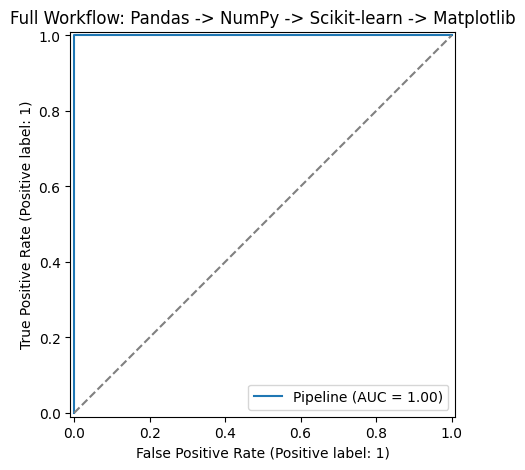


Each library's distinct role in this single workflow:
Pandas: loading, outlier clipping | NumPy: log transform, vectorized bucketing
Scikit-learn: preprocessing pipeline + model | Matplotlib: ROC curve diagnostic


In [16]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import train_test_split

# 1. PANDAS: load and clean
np.random.seed(88)
n = 800
combined_df = pd.DataFrame({
    "age": np.random.normal(38, 12, n),
    "spend": np.random.exponential(80, n),
    "segment": np.random.choice(["A", "B", "C"], n),
})
combined_df["spend"] = combined_df["spend"].clip(upper=combined_df["spend"].quantile(0.99))  # PANDAS cleaning

# 2. NUMPY: custom feature engineering
combined_df["log_spend"] = np.log1p(combined_df["spend"])   # NUMPY vectorized transform
combined_df["age_bucket"] = np.select(
    [combined_df["age"] < 30, combined_df["age"] < 50], ["young", "middle"], default="senior"
)

# 3. Target (for this demo)
combined_df["target"] = ((combined_df["log_spend"] > combined_df["log_spend"].median()) &
                           (combined_df["segment"] == "A")).astype(int)

# 4. SCIKIT-LEARN: preprocessing + model
X_combined = combined_df[["age", "log_spend", "segment", "age_bucket"]]
y_combined = combined_df["target"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_combined, y_combined, test_size=0.25, random_state=88, stratify=y_combined)

prep_combined = ColumnTransformer([
    ("num", StandardScaler(), ["age", "log_spend"]),
    ("cat", OneHotEncoder(), ["segment", "age_bucket"]),
])
combined_pipeline = Pipeline([("prep", prep_combined), ("model", RandomForestClassifier(n_estimators=100, random_state=88))])
combined_pipeline.fit(Xc_tr, yc_tr)

# 5. MATPLOTLIB: model diagnostic visualization
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(combined_pipeline, Xc_te, yc_te, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Full Workflow: Pandas -> NumPy -> Scikit-learn -> Matplotlib")
plt.show()

print("\nEach library's distinct role in this single workflow:")
print("Pandas: loading, outlier clipping | NumPy: log transform, vectorized bucketing")
print("Scikit-learn: preprocessing pipeline + model | Matplotlib: ROC curve diagnostic")


### Quiz (Chapter 88)
1. In the workflow above, identify exactly which line(s) belong to each of the four libraries' responsibilities.
2. Why is `np.select()` a NumPy-appropriate tool here rather than a Pandas `.apply()` with a Python function?
3. Why does the final diagnostic visualization step happen AFTER Scikit-learn's evaluation, not before?


---
# CHAPTER 89 — PROFESSIONAL NOTEBOOK ENGINEERING

## The Standard Notebook Structure
```
1. Problem Definition       (markdown -- one paragraph, no code)
2. Imports
3. Configuration            (paths, hyperparameters, random seeds -- ALL in one place, not scattered)
4. Data Loading
5. Data Validation           (Chapter 80's automated check)
6. EDA
7. Feature Engineering
8. Train/Test Split
9. Preprocessing
10. Baseline
11. Model Training
12. Evaluation
13. Cross Validation
14. Hyperparameter Tuning
15. Error Analysis
16. Interpretation
17. Final Model
18. Persistence
19. Conclusions              (markdown -- the business-facing summary)
```

## What Belongs in the Notebook vs. `src/`
| Notebook | `src/` |
|---|---|
| The narrative: why each decision was made | The actual reusable implementation |
| EDA visualizations and their interpretation | Data loading/cleaning functions |
| Calling `src/` functions and inspecting results | Custom transformers, Pipeline construction |
| The final written conclusions | Anything needing a unit test (Ch 79) |


In [17]:
# A CONFIGURATION block, exactly as section 3 above specifies -- all tunable settings
# collected in ONE place at the top of the notebook, not scattered across 40 cells
CONFIG = {
    "random_state": 42,
    "test_size": 0.2,
    "cv_folds": 5,
    "model_params": {"n_estimators": 200, "max_depth": 6},
    "decision_threshold": 0.35,
    "data_path": "/home/claude/data/raw/customers.csv",   # illustrative
}

print("Configuration block -- every downstream cell references CONFIG[...] instead of")
print("hardcoding these values inline. Changing an experiment now means editing ONE")
print("dictionary, not hunting through the entire notebook for scattered magic numbers.")
print(CONFIG)


Configuration block -- every downstream cell references CONFIG[...] instead of
hardcoding these values inline. Changing an experiment now means editing ONE
dictionary, not hunting through the entire notebook for scattered magic numbers.
{'random_state': 42, 'test_size': 0.2, 'cv_folds': 5, 'model_params': {'n_estimators': 200, 'max_depth': 6}, 'decision_threshold': 0.35, 'data_path': '/home/claude/data/raw/customers.csv'}


### Quiz (Chapter 89)
1. Why does collecting all configuration values into one block near the top of a notebook matter for reproducibility and experimentation speed?
2. Where should a custom transformer's actual class definition live — the notebook, or `src/`? Why?
3. What's the single-paragraph "Problem Definition" section for, and why does it deliberately contain no code?


---
# CHAPTER 90 — PRODUCTION CODE VS NOTEBOOK CODE

## The Contrast, Concretely
| Aspect | Learning/Notebook Code | Production Code |
|---|---|---|
| Structure | Loose cells, top-to-bottom narrative | Functions/classes with clear interfaces |
| Configuration | Hardcoded values inline | External config (Ch 89), environment variables |
| Logging | `print()` statements | Structured logging (`logging` module) with levels (INFO/WARNING/ERROR) |
| Validation | Assumed correct, rarely checked | Explicit input validation (Ch 68, 80) |
| Tests | None | Unit + integration tests (Ch 79) |
| Type hints | Rare | Standard, aids both correctness and IDE tooling |
| Error handling | Let exceptions propagate raw | Caught, logged, and handled deliberately with clear messages |
| Documentation | Markdown narrative cells | Docstrings on every public function/class |
| Reusability | Copy-paste across notebooks | Imported from a shared package |


In [18]:
import logging

# Configure structured logging -- the production replacement for scattered print() statements
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("churn_model")

def train_model_production_style(X_train, y_train, config: dict):
    """Train the churn model with production-appropriate logging and error handling."""
    logger.info(f"Starting training on {len(X_train)} samples with config: {config['model_params']}")

    try:
        from sklearn.ensemble import RandomForestClassifier
        model = RandomForestClassifier(**config["model_params"], random_state=config["random_state"])
        model.fit(X_train, y_train)
        logger.info("Training completed successfully.")
        return model
    except Exception as e:
        logger.error(f"Training failed: {e}")
        raise


X_demo90 = pd.DataFrame(np.random.randn(100, 3), columns=["a", "b", "c"])
y_demo90 = np.random.randint(0, 2, 100)
trained_model = train_model_production_style(X_demo90, y_demo90, CONFIG)


### Quiz (Chapter 90)
1. Why does structured logging (with levels like INFO/WARNING/ERROR) matter more than `print()` in a real production system?
2. List 4 specific differences between notebook code and production code from the table above.
3. Why does production code catch and log an exception before re-raising it, rather than just letting it propagate silently or crash unhandled?


---
# CHAPTER 91 — PERFORMANCE ENGINEERING

*(Consolidating Chapter 61's profiling discipline into a formal habit.)* The core question before any optimization: **"Where is the bottleneck?"** — never guess.

## The Profiling Checklist
1. Time each pipeline stage in isolation (Ch 61).
2. Check CPU vs. memory bound — is the process CPU-pegged, or waiting on I/O/memory swapping?
3. Check parallelism opportunities (`n_jobs=-1`) — but only at ONE nested level (Ch 61's oversubscription warning).
4. Check dataset size reduction opportunities — feature selection (Ch 32), dimensionality reduction (Ch 34), sparse representations (Ch 62).
5. Check algorithm choice — is a fundamentally faster-scaling algorithm available for this data size (Ch 22, 53)?


In [19]:
import time
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.datasets import make_classification

X_perf91, y_perf91 = make_classification(n_samples=20000, n_features=20, random_state=91)

timings = {}
for name, model in [
    ("RandomForest (n_estimators=300)", RandomForestClassifier(n_estimators=300, random_state=91)),
    ("HistGradientBoosting (default)", HistGradientBoostingClassifier(random_state=91)),
]:
    start = time.time()
    model.fit(X_perf91, y_perf91)
    timings[name] = time.time() - start

for name, t in timings.items():
    print(f"{name:<38}{t:.3f}s")

print(f"\nSwitching algorithm alone: {timings['RandomForest (n_estimators=300)'] / timings['HistGradientBoosting (default)']:.1f}x speedup")
print("This is usually a BIGGER win than micro-optimizing preprocessing code --")
print("exactly why profiling FIRST (to find where time is ACTUALLY spent) matters more")
print("than reflexively optimizing whatever code you happen to be looking at.")


RandomForest (n_estimators=300)       42.852s
HistGradientBoosting (default)        0.373s

Switching algorithm alone: 114.8x speedup
This is usually a BIGGER win than micro-optimizing preprocessing code --
exactly why profiling FIRST (to find where time is ACTUALLY spent) matters more
than reflexively optimizing whatever code you happen to be looking at.


### Quiz (Chapter 91)
1. What's the very first step of the profiling checklist, before any optimization attempt?
2. Why can switching algorithms sometimes yield a bigger performance win than micro-optimizing existing code?
3. Why should `n_jobs=-1` generally be applied at only one nested level?


---
# CHAPTER 92 — SECURITY AND MODEL PERSISTENCE

*(Consolidating Chapter 66's security note into its own focused treatment.)*

## The Core Risk
`joblib.load()` (and `pickle.load()`, which it's built on) can execute **arbitrary code** embedded in a maliciously crafted file during deserialization. This is not a theoretical concern — it's a well-documented, real attack vector.

## Practical Guidelines
- **Never** load a `joblib`/`pickle` file from an untrusted or unverified source — treat it exactly like running an unknown executable.
- For models shared across teams/organizations, verify provenance (who trained it, from what code/data) before loading, exactly as Chapter 67's versioning metadata supports.
- Consider safer serialization formats for genuinely untrusted or cross-organization contexts — e.g., ONNX (Open Neural Network Exchange, despite the name, supports classical ML too) stores a model's *computational graph* rather than arbitrary executable Python objects, closing this specific attack surface, at the cost of not supporting every possible Scikit-learn estimator/custom transformer.
- Environment/dependency pinning (Ch 66) is a *correctness* concern, distinct from — but related to — this *security* concern; both matter for trustworthy model deployment.


In [20]:
# A CONCEPTUAL demonstration of WHY this risk is real -- pickle can serialize
# arbitrary object state, including objects whose __reduce__ method executes code on load.
# (We do NOT actually construct a malicious payload here -- this is illustrative only.)

print("""
Conceptual illustration of the risk (NOT executed):

    import pickle, os

    class MaliciousPayload:
        def __reduce__(self):
            # __reduce__ tells pickle HOW to reconstruct this object --
            # an attacker can make it execute ARBITRARY code instead
            return (os.system, ('rm -rf /some/path',))

    # If a victim runs: pickle.load(open('innocent_looking_model.joblib', 'rb'))
    # the os.system() call executes IMMEDIATELY during deserialization --
    # BEFORE the victim ever gets a chance to inspect what "model" was loaded.
""")

print("This is exactly why 'only load models from sources you trust' is not optional")
print("advice -- joblib.load() on an untrusted file is equivalent to running")
print("unknown, unreviewed code with your own process's full permissions.")



Conceptual illustration of the risk (NOT executed):

    import pickle, os

    class MaliciousPayload:
        def __reduce__(self):
            # __reduce__ tells pickle HOW to reconstruct this object --
            # an attacker can make it execute ARBITRARY code instead
            return (os.system, ('rm -rf /some/path',))

    # If a victim runs: pickle.load(open('innocent_looking_model.joblib', 'rb'))
    # the os.system() call executes IMMEDIATELY during deserialization --
    # BEFORE the victim ever gets a chance to inspect what "model" was loaded.

This is exactly why 'only load models from sources you trust' is not optional
advice -- joblib.load() on an untrusted file is equivalent to running
unknown, unreviewed code with your own process's full permissions.


### Quiz (Chapter 92)
1. What specific mechanism allows a malicious pickle/joblib file to execute arbitrary code?
2. What's a safer serialization alternative for genuinely untrusted/cross-organization model sharing, and what's its tradeoff?
3. How does model versioning (Ch 67) support security, not just reproducibility?


---
# CHAPTER 93 — MODEL GOVERNANCE

## Practical Concepts
| Concept | What it means in practice |
|---|---|
| **Model version** | Chapter 67's manifest — which exact artifact is deployed, right now |
| **Training dataset** | Chapter 67's data hash — exactly what data produced this model |
| **Feature definitions** | A documented, versioned specification of every feature's exact computation (critical when feature engineering logic evolves — Chapter 78's `features.py`) |
| **Evaluation metrics** | Chapter 27's chosen metrics, recorded alongside the model (Chapter 82's Model Card) |
| **Approval** | A defined process/sign-off before a new model version replaces the currently-deployed one — who reviews, what threshold must be met |
| **Reproducibility** | Chapter 60's random-state discipline + Chapter 66's version pinning, together |
| **Auditability** | Can you answer, months later, "why did the model make this specific prediction on this specific date" — requires versioning + logging + Model Cards together |
| **Documentation** | Chapter 82's Model Card, kept current with every model version |

## Why This Matters Beyond "Best Practice"
For models with genuine business or regulatory impact (credit decisions, hiring, healthcare), governance isn't optional — many industries have explicit regulatory requirements for model explainability, audit trails, and documented decision processes. Even without formal regulation, governance is what separates "a model we can trust and maintain" from "a black box nobody fully understands six months after the original author has moved to a different project."


### Interview Insight
**Q: Six months after a model was deployed, a regulator (or an internal audit) asks why a specific customer was denied a loan by the model on a specific date. What would you need to have in place to answer confidently?**
A: The exact model version deployed on that date (Ch 67's versioning), the exact training data and feature definitions that produced it (data hash + documented feature specs), the model's recorded evaluation metrics and known limitations at approval time (Ch 82's Model Card), and ideally a logged record of the specific input features and prediction for that individual case (production logging, Ch 90). Together, these let you reconstruct exactly what happened and why — reproducing the specific prediction, explaining the model's reasoning via interpretability tools (Ch 47–49) applied to that specific case, and confirming the decision was made by an approved, documented model version rather than some unversioned or unauthorized variant.

### Quiz (Chapter 93)
1. List the 8 governance concepts from this chapter's table.
2. Why does auditability require versioning, logging, AND documentation together — why isn't any single one sufficient alone?
3. Beyond "best practice," what real-world requirement can make governance mandatory rather than optional?


---
# CHAPTER 94 — BUSINESS INTERPRETATION

## Translating ML Output Into Business Decisions

**Instead of:**
> "Accuracy = 91%."

**Say:**
> "The model correctly classifies 91% of customers overall, but because a missed churner costs roughly 4x more than an unnecessary retention offer, we specifically optimized the decision threshold for recall over raw accuracy — at the deployed threshold, we catch 78% of genuine churners at the cost of a 15% false-alarm rate among retained customers, which our cost analysis shows minimizes total expected cost."

## The Translation Discipline
| Technical statement | Business translation |
|---|---|
| "ROC-AUC = 0.87" | "The model reliably ranks at-risk customers above low-risk ones — useful for prioritizing a limited outreach budget" |
| "Precision = 0.65 at the deployed threshold" | "About 2 in 3 customers we flag for outreach are genuinely at risk — the other 1 in 3 receive an unnecessary but low-cost offer" |
| "The model shows high variance (Ch 50)" | "Performance is sensitive to exactly which customers happen to be in our training data — we recommend collecting more data before fully trusting this model's generalization" |
| "Feature X has high permutation importance" | "Customers with characteristic X are a key signal the model relies on — worth investigating WHY that relationship exists before acting on it directly (correlation ≠ causation)" |
| "The model is well-calibrated (Ch 31)" | "A predicted 70% churn probability genuinely corresponds to about 70% of similar customers churning — the actual number can be trusted, not just the ranking" |


In [21]:
def translate_metrics_to_business(roc_auc, precision, recall, threshold, cost_fp, cost_fn):
    """A genuine reusable function -- generates a business-readable summary from raw metrics."""
    cost_ratio = cost_fn / cost_fp
    summary = f"""
BUSINESS SUMMARY
-----------------
Model ranking quality: {'Strong' if roc_auc > 0.8 else 'Moderate' if roc_auc > 0.7 else 'Weak'} (ROC-AUC={roc_auc:.2f})
  -- the model {'reliably' if roc_auc > 0.8 else 'reasonably'} distinguishes at-risk from low-risk cases.

At the deployed threshold ({threshold:.2f}):
  - {precision:.0%} of flagged cases are genuinely at-risk (precision)
  - {recall:.0%} of all genuinely at-risk cases are caught (recall)

This threshold was chosen assuming a missed case costs {cost_ratio:.0f}x an unnecessary
flag -- if this cost assumption changes, the threshold should be RE-OPTIMIZED (Ch 30),
not left at its current value.
"""
    return summary

print(translate_metrics_to_business(roc_auc=0.744, precision=0.42, recall=0.78, threshold=0.166, cost_fp=30, cost_fn=120))



BUSINESS SUMMARY
-----------------
Model ranking quality: Moderate (ROC-AUC=0.74)
  -- the model reasonably distinguishes at-risk from low-risk cases.

At the deployed threshold (0.17):
  - 42% of flagged cases are genuinely at-risk (precision)
  - 78% of all genuinely at-risk cases are caught (recall)

This threshold was chosen assuming a missed case costs 4x an unnecessary
flag -- if this cost assumption changes, the threshold should be RE-OPTIMIZED (Ch 30),
not left at its current value.



### Quiz (Chapter 94)
1. Translate "F1 score = 0.68" into a business-readable sentence for a non-technical stakeholder.
2. Why does the translation of "the model is well-calibrated" specifically distinguish trusting the actual number from trusting only the ranking?
3. Why must a business translation of a chosen threshold always mention the cost assumption it depends on?


---
# CHAPTER 95 — MODEL SELECTION MASTERCLASS

Three unfamiliar scenarios. For each, reason through preprocessing, model family, metric, validation strategy, and interpretation method **before** reading the suggested reasoning — then critique your own answer against it, exactly as a senior engineer would in a real design review.

## Scenario A
*10,000 rows, 200 features (mostly correlated sensor readings), binary target, need genuine interpretability for a regulatory audit.*

<details><summary>Suggested reasoning</summary>

- **Preprocessing**: Given heavy correlation among 200 features, consider `SelectFromModel`/`RFECV` (Ch 32) or `PCA` (Ch 34–35) to reduce dimensionality — but PCA sacrifices direct interpretability of ORIGINAL features, which conflicts with the audit requirement; feature selection (keeping original features, just fewer of them) is likely the better fit here specifically because of the interpretability constraint.
- **Model family**: Logistic Regression (with L1/Lasso-style regularization for further automatic feature sparsity, Ch 14) or a single shallow Decision Tree — both directly interpretable, unlike an ensemble.
- **Metric**: Depends on the actual regulatory/business question — but interpretability requirements often also imply a need for calibrated, explainable probabilities (Ch 31), not just ranking.
- **Validation**: Standard `StratifiedKFold` unless there's a grouping structure (Ch 55) in the sensor data (e.g., multiple readings per device/unit) — check for this explicitly.
- **Interpretation**: Coefficients directly (Ch 47), since the chosen model family supports it natively — no need for permutation importance/PDP here, though they'd still work as a secondary check.
</details>

## Scenario B
*500 million rows (streaming), continuous target, need predictions within 50ms, tolerant of retraining weekly.*

<details><summary>Suggested reasoning</summary>

- **Preprocessing**: Must be fast and stateless-per-batch or incrementally updatable; avoid anything requiring a full-dataset pass at inference time.
- **Model family**: `SGDRegressor` (linear, naturally supports incremental `partial_fit()`, extremely fast inference) is a strong candidate given both the scale and latency constraints (Ch 53, 61); a large tree ensemble likely violates the 50ms budget.
- **Metric**: MAE/RMSE (Ch 27), chosen based on whether large errors should be disproportionately penalized.
- **Validation**: If genuinely time-ordered (streaming), `TimeSeriesSplit` (Ch 54), not ordinary K-Fold.
- **Interpretation**: Linear coefficients (Ch 47) — a side benefit of the latency-driven model choice.
</details>

## Scenario C
*2,000 rows, mostly categorical features, severe class imbalance (2% positive), false positives are cheap but false negatives are catastrophic (e.g., safety-critical failure prediction).*

<details><summary>Suggested reasoning</summary>

- **Preprocessing**: `OneHotEncoder` for categoricals (Ch 6); given the small dataset, be cautious about high-cardinality columns exploding dimensionality relative to sample count (Ch 62's dimensionality concern, even without needing genuine sparse-matrix memory optimization at this scale).
- **Model family**: With only 2,000 rows, favor simpler models less prone to overfitting (Logistic Regression with `class_weight="balanced"`, or a modestly-sized Random Forest) over an aggressively-tuned boosting ensemble.
- **Metric**: Recall-heavy focus given the catastrophic-false-negative cost structure (Ch 27, 30) — likely optimize threshold for very high recall even at the cost of many false positives, given they're stated to be cheap.
- **Validation**: `StratifiedKFold` mandatory given the severe imbalance (Ch 4, 23) on this already-small dataset.
- **Interpretation**: Given the safety-critical framing, interpretability likely matters for building trust in the model's flagged cases — favor a model family supporting direct interpretation.
</details>

### Quiz (Chapter 95)
Before reading any of the suggested reasonings above, write your own full answer for at least one scenario, then compare — where did you agree, and where did your reasoning diverge?


---
# CHAPTER 96 — MASTER CAPSTONE

**Do not scroll to see any reference code before attempting this yourself.**

## Business Problem
An online education platform wants to predict which enrolled students are at risk of **not completing** their course, so instructors can proactively offer support.

## Dataset Description
`capstone_students` (generated below) — one row per enrolled student.

## Feature Dictionary
| Column | Type | Description |
|---|---|---|
| `days_since_enrollment` | numerical | Days since the student enrolled |
| `avg_session_minutes` | numerical | Average length of study sessions |
| `num_modules_completed` | numerical | Modules completed so far |
| `forum_posts` | numerical | Number of discussion forum posts |
| `course_category` | categorical | Subject area |
| `device_type` | categorical | Primary device used (Desktop/Mobile/Tablet) |
| `completed` | binary target | 1 = completed the course |

## Business Objective
Flag at-risk (likely non-completing) students early enough for meaningful instructor intervention.

## Technical Objective
A well-validated classifier with a threshold chosen against a stated cost assumption (a missed at-risk student costs 3x an unnecessary check-in).

## Constraints
Build the ENTIRE workflow yourself: EDA → cleaning → feature engineering → split → preprocessing → pipeline → baseline → multiple models → CV → tuning → feature selection/importance → interpretation → error analysis → final model → persistence → inference pipeline → business report.

## Expected Deliverables
Every stage above, executed and written up, ending in a genuine business recommendation.

---
## The Dataset (generated for you — the analysis is yours to build)


In [22]:
np.random.seed(96)
n_cap2 = 1200
capstone_students = pd.DataFrame({
    "days_since_enrollment": np.random.exponential(35, n_cap2).round(0),
    "avg_session_minutes": np.random.exponential(18, n_cap2).round(1),
    "num_modules_completed": np.random.poisson(4, n_cap2),
    "forum_posts": np.random.poisson(1.5, n_cap2),
    "course_category": np.random.choice(["Programming", "Business", "Design", "Data Science"], n_cap2),
    "device_type": np.random.choice(["Desktop", "Mobile", "Tablet"], n_cap2, p=[0.55, 0.35, 0.10]),
})
complete_logit = (
    -1.0 + capstone_students["num_modules_completed"] * 0.35 + capstone_students["forum_posts"] * 0.25
    + capstone_students["avg_session_minutes"] * 0.02 - capstone_students["days_since_enrollment"] * 0.005
)
capstone_students["completed"] = (np.random.rand(n_cap2) < 1 / (1 + np.exp(-complete_logit))).astype(int)

# Realistic data-quality issues
capstone_students.loc[np.random.choice(n_cap2, 45, replace=False), "avg_session_minutes"] = np.nan
capstone_students.loc[np.random.choice(n_cap2, 3, replace=False), "days_since_enrollment"] = -5   # impossible

print(f"Shape: {capstone_students.shape}")
print(f"Completion rate: {capstone_students['completed'].mean():.3f}")
capstone_students.head(3)


Shape: (1200, 7)
Completion rate: 0.691


,days_since_enrollment,avg_session_minutes,num_modules_completed,forum_posts,course_category,device_type,completed
0,8.0,12.1,5,3,Business,Desktop,1
1,84.0,20.0,4,1,Design,Mobile,0
2,59.0,22.0,8,2,Programming,Desktop,1


### Your Workspace — build the complete project below

In [23]:
# Step 1: your work here


In [24]:
# Step 2: your work here


In [25]:
# Step 3: your work here


In [26]:
# Step 4: your work here


In [27]:
# Step 5: your work here


In [28]:
# Step 6: your work here


In [29]:
# Step 7: your work here


In [30]:
# Step 8: your work here


---
## Self-Review Checklist (score yourself as a Senior ML Engineer would)
- [ ] Data quality: found and handled the impossible value AND the missing data correctly
- [ ] EDA: at least univariate + bivariate analysis performed and interpreted
- [ ] No leakage: all preprocessing correctly scoped to training folds only
- [ ] Multiple models fairly compared (identical CV folds, multiple metrics)
- [ ] Threshold chosen against the stated 3:1 cost ratio, not left at 0.5
- [ ] Feature importance computed and sanity-checked against domain expectations
- [ ] Segment-level error analysis performed (e.g., by `course_category` or `device_type`)
- [ ] Final model persisted with a versioned metadata manifest
- [ ] A genuine, specific business recommendation written, not just metrics reported

### Reveal a Reference Approach
If you'd like a worked reference solution for this capstone, ask, and one will be built for you using exactly the techniques from Notebooks 1–13 — the same structure as Chapter 72's Customer Churn project.


---
# CHAPTER 97 — MOCK INTERVIEW

A realistic, mixed-format closing mock interview. Answer each **before** revealing the ideal answer.

---
### Question 1 (Theory)
**"Explain the estimator/transformer/predictor distinction, and why 'estimator' is the umbrella term."**
<details><summary>Reveal</summary>
Estimator = anything with `.fit()` — the base role. Transformer additionally has `.transform()`/`.fit_transform()` (scalers, encoders — learns parameters ABOUT the data). Predictor additionally has `.predict()` (models — learns a mapping TO a target). "Estimator" is the umbrella because literally everything in this hierarchy, including scalers/encoders, "estimates" something from data via `.fit()`. (Ch 2)
</details>

### Question 2 (Coding)
**"Write a function that fairly compares 3 classifiers using identical preprocessing and CV folds."**
<details><summary>Reveal</summary>
See Chapter 52's `compare_models()` — the key elements: wrap every model in an identical Pipeline structure, pass the SAME seeded `StratifiedKFold` object to every `cross_validate()` call, report multiple metrics plus timing.
</details>

### Question 3 (Debugging)
**"`ValueError: Found unknown categories ['X'] during transform` — diagnose and fix."**
<details><summary>Reveal</summary>
A OneHotEncoder is seeing a category at transform-time it never saw during fit. Fix: `handle_unknown="ignore"` for production robustness; but first, verify whether "X" is a legitimate new category or a data-quality bug worth investigating. (Ch 6, 57, 85)
</details>

### Question 4 (Leakage)
**"Walk through why fitting a scaler on the full dataset before `train_test_split` is wrong."**
<details><summary>Reveal</summary>
The scaler's learned mean/std would be computed using test-set values too, so the "test set" is no longer genuinely unseen by anything that touched training — even though the model itself never sees test labels, the preprocessing parameters used to prepare training data were informed by test data, inflating apparent generalization. (Ch 5, 11, 56)
</details>

### Question 5 (Imbalance)
**"Your fraud model has 99% accuracy. Are you satisfied? What do you check next?"**
<details><summary>Reveal</summary>
No — with typically <1% fraud rates, 99% accuracy could be achieved by predicting "not fraud" for everything. Check the confusion matrix, PR-AUC/Average Precision specifically (not ROC-AUC alone), and recall at a business-relevant threshold. (Ch 27, 29, 55, 74)
</details>

### Question 6 (Ensembles)
**"Explain bagging vs boosting in terms of what each primarily reduces."**
<details><summary>Reveal</summary>
Bagging trains models independently on bootstrap samples, averaging to reduce VARIANCE. Boosting trains models sequentially, each correcting prior errors, primarily reducing BIAS (at higher overfitting risk if under-regularized). (Ch 20)
</details>

### Question 7 (Production)
**"Why persist the entire Pipeline, not just the trained model?"**
<details><summary>Reveal</summary>
If only the model is saved, inference code must separately re-implement identical preprocessing (imputation values, scaling stats, encoding categories) — any discrepancy silently produces wrong predictions with no error. Saving the whole fitted Pipeline guarantees training-time and inference-time preprocessing are always identical by construction. (Ch 66)
</details>

### Question 8 (Harder Follow-Up)
**"Your calibrated, well-tuned, leakage-free model still gets rejected by business stakeholders. What's your process for figuring out why?"**
<details><summary>Reveal</summary>
Technical correctness doesn't guarantee business acceptance. Check: interpretability (can you explain individual flagged cases — Ch 47–49?), segment-level performance (is it failing specifically for a segment stakeholders care about — Ch 81?), whether the chosen metric/threshold actually reflects the real business cost structure (Ch 30, 94), and whether the business's actual concern is something the model was never designed to address at all (a scope/expectations mismatch, not a technical flaw). (Ch 86 Scenario 5, Ch 94)
</details>

---
## Final Self-Score

Rate yourself 1–5 on: Theory recall, Live coding fluency, Debugging speed, Leakage vigilance, Business translation. A **"Job Ready"** bar is roughly a 4+ average.


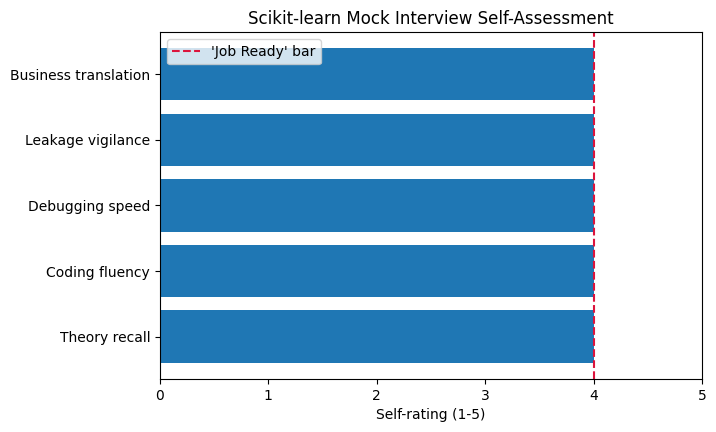

Average score: 4.0


In [31]:
categories_score_sk = ["Theory recall", "Coding fluency", "Debugging speed", "Leakage vigilance", "Business translation"]
my_scores_sk = [4, 4, 4, 4, 4]   # <-- EDIT based on your honest self-assessment

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(categories_score_sk, my_scores_sk, color="tab:blue")
ax.set_xlim(0, 5)
ax.axvline(4, color="crimson", linestyle="--", label="'Job Ready' bar")
ax.set_xlabel("Self-rating (1-5)")
ax.set_title("Scikit-learn Mock Interview Self-Assessment")
ax.legend()
plt.show()
print(f"Average score: {np.mean(my_scores_sk):.1f}")


---

# COURSE COMPLETE — FINAL CLASSIFICATION

| Level | Signal |
|---|---|
| **Beginner** | Comfortable with `model.fit(X, y)`, still consulting docs for every new estimator |
| **Scikit-learn Learner** | Fluent with the Estimator API, builds basic Pipelines unaided |
| **Intermediate** | Builds full ColumnTransformer + Pipeline workflows, understands leakage conceptually |
| **Advanced** | Debugs unfamiliar errors independently, tunes hyperparameters via GridSearchCV/RandomizedSearchCV confidently |
| **Job Ready** | Passes this notebook's mock interview comfortably, completed the capstone independently, recognizes and prevents every leakage pattern from Chapter 56 |
| **Strong ML Engineer** | Additionally reasons fluently about production concerns (persistence, monitoring, versioning) and translates technical results into business decisions |
| **Scikit-learn Specialist** | Additionally can critique and improve others' ML pipelines confidently, and reasons well about when Scikit-learn is (or isn't) the right tool versus XGBoost/deep learning/statsmodels |

---

# END OF THE SCIKIT-LEARN MASTERY COURSE

You have completed all 97 chapters across 14 notebooks:
1. Chapters 1–5 — Ecosystem, Estimator API, Data Representation, Train/Test Split, Scaling
2. Chapters 6–10 — Encoding, Imputation, Feature Generation, Custom Transformers, ColumnTransformer
3. Chapters 11–15 — Pipelines, FeatureUnion, Supervised Learning Map, Linear Regression Family, Logistic Regression
4. Chapters 16–20 — KNN, SVM, Naive Bayes, Decision Trees, Ensemble Learning
5. Chapters 21–25 — Random Forest Integration, Gradient Boosting, Model Selection, Cross-Validation, Hyperparameter Tuning
6. Chapters 26–31 — Advanced Search, Evaluation Metrics, Confusion Matrix, ROC/PR, Threshold Optimization, Calibration
7. Chapters 32–38 — Feature Selection, Mutual Information, Dimensionality Reduction, PCA, Clustering, Cluster Evaluation, Anomaly Detection
8. Chapters 39–45 — Semi-Supervised, Composed Estimators, Meta-Estimators, Multi-Class/Label/Output, Imbalanced Data
9. Chapters 46–52 — Sample Weights, Feature Importance, Permutation Importance, Partial Dependence, Learning/Validation Curves, Model Comparison
10. Chapters 53–60 — Model Selection Strategy, Time Series, Grouped Data, Data Leakage Module, Pipeline Debugging, Model Inspection, Feature Names, Reproducibility
11. Chapters 61–66 — Performance, Sparse Matrices, Text ML, NLP Pipelines, Computer Vision, Model Persistence
12. Chapters 67–72 — Versioning, Production Inference, Deployment, MLOps, Monitoring, **Project #1: Customer Churn**
13. Chapters 73–77 — **Projects #2–6**: Credit Default, Fraud Detection, House Price Regression, Customer Segmentation, Text Classification
14. Chapters 78–97 — Engineering Discipline, Full Interview Mastery, **Master Capstone**, **Mock Interview**

You are equipped to work as a professional ML engineer using Scikit-learn — not just to call `.fit()` and `.predict()`, but to reason about data leakage, validate correctly, choose the right metric for the actual business problem, debug confidently, and communicate results in language stakeholders can act on.
